# Stage 6 — Signal-domain verification (no Grad-CAM)

Stages 3–4 found two candidate regions using **Grad-CAM** — a model-internal signal that shows what the CRNN *attended to*, not what is physically present in the raw audio. This notebook re-checks both candidates **completely independently of the model**: no CRNN, no Grad-CAM, no GPU required. It works directly on the raw waveform.

For each candidate cell — **Apex, S1, 100–200 Hz** and **LUSB, S2, 200–300 Hz** — this notebook:
1. Zero-phase Butterworth band-pass filters each full recording to the candidate's frequency band.
2. Slices out just the samples inside that recording's phase-label time intervals (from Stage 2 / Stage 5's phase boundaries — reused unchanged, not re-segmented).
3. Computes four physical descriptors on that phase-restricted signal: **log-bandpower / RMS energy**, **mean spectral density in the band** (Welch PSD), **spectral entropy**, and **normalized band power** (the band's share of 0–800 Hz total power).
4. Averages to one value per **patient** per descriptor (not per recording — same rule Stage 4 used for Grad-CAM energy).
5. Compares MI vs. Normal per candidate x descriptor with **Mann-Whitney U**, **Cliff's delta**, a **bootstrap 95% confidence interval** on delta, and **BH-FDR correction** across all tests — run on the development cohort, the locked confirmation cohort, an **extended confirmation cohort** (see Section 5), and pooled.

Everything is saved to `artifacts/06_signal_domain_verification/`. This notebook only reads artifacts already produced by Stages 1, 2, and 5 — **no other stage needs to be re-run.**

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
# ---- Setup ----------------------------------------------------------------
import sys
import json
import datetime
import pathlib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

package_path = "/content/drive/MyDrive/Research 2026/mi_marker_pipeline"
if package_path not in sys.path:

    sys.path.insert(0, package_path)

from pipeline_common import config
from pipeline_common.audio import load_and_resample, pad_or_trim
from pipeline_common.signal_verification import (
    compute_recording_descriptor_table, aggregate_descriptors_to_patient_level,
    run_signal_domain_tests, DESCRIPTOR_COLUMNS,
)

import random
random.seed(config.SEED); np.random.seed(config.SEED)

SPLIT_DIR = config.ARTIFACTS_DIR / "01_split"
SEG_DIR = config.ARTIFACTS_DIR / "02_segmentation" / "heuristic"
CONFIRM_DIR = config.ARTIFACTS_DIR / "05_confirmation"
STAGE_DIR = config.ARTIFACTS_DIR / "06_signal_domain_verification"
STAGE_DIR.mkdir(parents=True, exist_ok=True)

# No model, no GPU, no Grad-CAM anywhere in this notebook -- deliberately.
print("Saving this stage's output to:", STAGE_DIR)

Saving this stage's output to: /content/drive/MyDrive/Research 2026/mi_marker_pipeline/artifacts/06_signal_domain_verification


## 1. Load metadata + phase boundaries (development + confirmation, unchanged from earlier stages)

Reuses Stage 1's split metadata and Stage 2 / Stage 5's already-computed phase boundaries directly -- this notebook does not re-segment anything, so any difference found here can't be attributed to a different segmentation run.

In [3]:
metadata_df = pd.read_csv(SPLIT_DIR / "metadata_with_split.csv")
metadata_df = metadata_df.rename(columns={"split": "cohort"})

boundaries_dev = pd.read_csv(SEG_DIR / "phase_boundaries.csv")
boundaries_confirm = pd.read_csv(CONFIRM_DIR / "phase_boundaries_confirmation.csv")
boundaries_df = pd.concat([boundaries_dev, boundaries_confirm], ignore_index=True)

print(f"{len(metadata_df)} recordings total "
      f"({(metadata_df['cohort']=='development').sum()} development, "
      f"{(metadata_df['cohort']=='confirmation').sum()} confirmation)")
print(f"{len(boundaries_df)} phase-boundary rows (both cohorts)")

# ---- quick integrity check on the cohort split (catches a mislabeled/leaked cohort early) --
dev_patients = set(metadata_df.loc[metadata_df['cohort']=='development', 'patient_id'])
confirm_patients = set(metadata_df.loc[metadata_df['cohort']=='confirmation', 'patient_id'])
assert dev_patients.isdisjoint(confirm_patients), "BUG: a patient appears in both cohorts"
assert set(boundaries_confirm['patient_id']) <= confirm_patients, \
    "BUG: phase_boundaries_confirmation.csv contains a patient not in the confirmation split"
print(f"cohort integrity OK -- {len(dev_patients)} development / {len(confirm_patients)} "
      f"confirmation patients, zero overlap")

3360 recordings total (2688 development, 672 confirmation)
188167 phase-boundary rows (both cohorts)
cohort integrity OK -- 112 development / 28 confirmation patients, zero overlap


## 2. The two candidates being verified

Unchanged from Stage 4's occlusion-validated, Stage 5-confirmed shortlist -- this notebook does not search for new candidates, it only re-tests these two with a different, model-free method.

In [4]:
CANDIDATES = [
    {"name": "apex_S1_100_200", "site": "apex", "phase_label": "S1",
     "freq_low": 100.0, "freq_high": 200.0},
    {"name": "lusb_S2_200_300", "site": "lusb", "phase_label": "S2",
     "freq_low": 200.0, "freq_high": 300.0},
]
FILTER_ORDER = 4
pd.DataFrame(CANDIDATES)

,name,site,phase_label,freq_low,freq_high
0,apex_S1_100_200,apex,S1,100.0,200.0
1,lusb_S2_200_300,lusb,S2,200.0,300.0


## 3. Band-pass + physical descriptors (no model, no Grad-CAM)

`load_signal_fn` loads and resamples/pads each recording exactly like every earlier stage (same `config.SAMPLE_RATE`, same `config.CLIP_SECONDS`) so the only thing different from Stages 3–5 is that the CRNN and Grad-CAM are never invoked here.

In [5]:
def load_signal_fn(filepath):
    signal = load_and_resample(filepath, config.SAMPLE_RATE)
    return pad_or_trim(signal, config.SAMPLE_RATE, config.CLIP_SECONDS)

recording_descriptors = compute_recording_descriptor_table(
    metadata_df, boundaries_df, CANDIDATES,
    sr=config.SAMPLE_RATE, freq_high_total=config.FREQUENCY_HIGH,
    clip_seconds=config.CLIP_SECONDS, load_signal_fn=load_signal_fn,
    filter_order=FILTER_ORDER,
)

recording_descriptors.to_csv(STAGE_DIR / "recording_level_descriptors.csv", index=False)
print(f"{len(recording_descriptors)} (recording x candidate) rows -- "
      f"{recording_descriptors['patient_id'].nunique()} unique patients touched")
recording_descriptors.head()

1676 (recording x candidate) rows -- 140 unique patients touched


,candidate,site,phase_label,freq_low,freq_high,filepath,patient_id,class_name,cohort,log_bandpower_db,mean_psd_band,spectral_entropy,normalized_band_power,n_samples
0,apex_S1_100_200,apex,S1,100.0,200.0,/content/drive/MyDrive/Research 2026/Segmented...,P0071,Normal,development,-72.126848,5.222399e-10,0.386331,0.026377,3200
1,apex_S1_100_200,apex,S1,100.0,200.0,/content/drive/MyDrive/Research 2026/Segmented...,P0071,Normal,development,-70.657606,9.534830e-10,0.442003,0.047071,2000
2,apex_S1_100_200,apex,S1,100.0,200.0,/content/drive/MyDrive/Research 2026/Segmented...,P0071,Normal,development,-61.630693,6.360680e-09,0.571660,0.097082,2400
3,apex_S1_100_200,apex,S1,100.0,200.0,/content/drive/MyDrive/Research 2026/Segmented...,P0071,Normal,development,-69.928780,1.004710e-09,0.427569,0.044583,2400
4,apex_S1_100_200,apex,S1,100.0,200.0,/content/drive/MyDrive/Research 2026/Segmented...,P0071,Normal,development,-71.107928,7.051256e-10,0.469348,0.035737,2800


## 4. Aggregate to patient level

The statistical unit is the **patient**, not the recording -- identical rule to Stage 4's Grad-CAM energy aggregation, applied here to the four physical descriptors instead.

In [6]:
patient_descriptors = aggregate_descriptors_to_patient_level(recording_descriptors)
patient_descriptors.to_csv(STAGE_DIR / "patient_level_descriptors.csv", index=False)

print(patient_descriptors.groupby(["candidate", "cohort", "class_name"])["patient_id"]
      .nunique().unstack(fill_value=0))
patient_descriptors.head()

class_name                    Myocardial  Normal
candidate       cohort                          
apex_S1_100_200 confirmation          14      14
                development           55      56
lusb_S2_200_300 confirmation          14      14
                development           56      56


,patient_id,class_name,cohort,candidate,site,phase_label,freq_low,freq_high,log_bandpower_db,mean_psd_band,spectral_entropy,normalized_band_power
0,P0001,Myocardial,development,apex_S1_100_200,apex,S1,100.0,200.0,-64.134629,3.569968e-09,0.518048,0.078792
1,P0001,Myocardial,development,lusb_S2_200_300,lusb,S2,200.0,300.0,-77.425620,3.050880e-09,0.388289,0.002417
2,P0002,Myocardial,development,lusb_S2_200_300,lusb,S2,200.0,300.0,-66.594515,2.196301e-09,0.548926,0.039474
3,P0003,Myocardial,development,apex_S1_100_200,apex,S1,100.0,200.0,-67.608221,1.781426e-09,0.387656,0.008663
4,P0003,Myocardial,development,lusb_S2_200_300,lusb,S2,200.0,300.0,-73.671957,6.391562e-10,0.408429,0.004503


## 5. Extended confirmation grouping (larger *n*, Stage 6-only)

The locked confirmation cohort from Stage 1 has only 14 MI + 14 Normal patients -- on the first run of this notebook, none of the 8 (candidate x descriptor) tests reached significance there, even though the same effects were significant in development and pooled. A quick power check explains why: for an effect around Cliff's delta $\approx$ 0.40 (roughly what development showed), the standard Mann-Whitney/Cliff's-delta sample-size approximation (Noether 1987) needs on the order of 13–16 patients **per group** for 80% power at $\alpha=0.05$ -- confirmation sits right at that threshold, so a non-significant result there is easily explained by insufficient power, not necessarily a real absence of effect.

**Important caveat -- read before trusting this section:** the underlying dataset has only 140 patients total (112 development + 28 confirmation), fixed since Stage 1. There is no way to add genuinely new, never-before-touched patients from inside Stage 6 alone. What this section does instead is build an **extended confirmation grouping**: the original 14+14 locked confirmation patients, plus additional patients drawn (without replacement, fixed seed, stratified by class) from the *development* pool, purely to see whether the effect holds up as sample size grows. This is **not** a stronger independent replication than the `pooled` analysis already computed below -- the added patients were part of the data used to train the classifier and discover the candidates in Stages 3–4. Treat `confirmation_extended` as a **power-curve diagnostic**, not as new out-of-sample evidence. The original `confirmation` cohort (n=14/14) remains the only grouping in this notebook that is a genuine, untouched hold-out test.

`EXTENDED_CONFIRMATION_TARGET_PER_CLASS` is the target patient count per class; it's automatically capped at however many development patients of that class actually exist, so asking for more than the dataset has just gives you the full pooled set back.

In [7]:
EXTENDED_CONFIRMATION_TARGET_PER_CLASS = 30   # tune this; capped by available development pool
EXTENDED_CONFIRMATION_SEED = 123              # separate from config.SEED -- this resampling is a
                                              # Stage 6-only analysis choice, not part of the
                                              # pipeline's core reproducibility seed

rng_extend = np.random.default_rng(EXTENDED_CONFIRMATION_SEED)

confirmation_patients_by_class = (
    metadata_df[metadata_df["cohort"] == "confirmation"]
    .drop_duplicates("patient_id").groupby("class_name")["patient_id"].apply(list).to_dict()
)
development_patients_by_class = (
    metadata_df[metadata_df["cohort"] == "development"]
    .drop_duplicates("patient_id").groupby("class_name")["patient_id"].apply(list).to_dict()
)

extended_confirmation_patient_ids = set()
extension_log = []
for class_name in config.CLASSES:
    base = list(confirmation_patients_by_class.get(class_name, []))
    pool = list(development_patients_by_class.get(class_name, []))
    n_needed = min(max(EXTENDED_CONFIRMATION_TARGET_PER_CLASS - len(base), 0), len(pool))
    added = list(rng_extend.choice(pool, size=n_needed, replace=False)) if n_needed > 0 else []
    extended_confirmation_patient_ids.update(base)
    extended_confirmation_patient_ids.update(added)
    extension_log.append({"class_name": class_name, "original_confirmation_n": len(base),
                          "added_from_development_n": len(added),
                          "extended_confirmation_n": len(base) + len(added),
                          "development_pool_available": len(pool)})

extension_log_df = pd.DataFrame(extension_log)
extension_log_df.to_csv(STAGE_DIR / "extended_confirmation_composition.csv", index=False)
extension_log_df

,class_name,original_confirmation_n,added_from_development_n,extended_confirmation_n,development_pool_available
0,Normal,14,16,30,56
1,Myocardial,14,16,30,56


## 6. MI vs. Normal: Mann-Whitney, Cliff's delta, bootstrap CI, FDR

Run on the **development** cohort, the **confirmation** cohort (genuine hold-out, n=14/14), the **confirmation_extended** grouping (power diagnostic, see Section 5 caveat), and **pooled** (both). BH-FDR is applied within each of these four runs across all (candidate x descriptor) tests (2 candidates x 4 descriptors = 8 tests per run).

In [8]:
all_results = []
cohort_groupings = [
    ("development", patient_descriptors["cohort"] == "development"),
    ("confirmation", patient_descriptors["cohort"] == "confirmation"),
    ("confirmation_extended", patient_descriptors["patient_id"].isin(extended_confirmation_patient_ids)),
    ("pooled", pd.Series(True, index=patient_descriptors.index)),
]

for cohort_label, mask in cohort_groupings:
    subset = patient_descriptors[mask]
    res = run_signal_domain_tests(subset, descriptor_cols=DESCRIPTOR_COLUMNS,
                                  min_patients_per_group=config.MIN_PATIENTS_PER_GROUP_FOR_TEST,
                                  alpha=config.FDR_ALPHA, ci=0.95, n_boot=2000, seed=config.SEED,
                                  positive_class=config.CLASSES[1], negative_class=config.CLASSES[0])
    res.insert(0, "analysis_cohort", cohort_label)
    all_results.append(res)

signal_domain_results = pd.concat(all_results, ignore_index=True)

# A directional check specific to what Grad-CAM found: for the three band-energy descriptors,
# Stage 4/5 found MI energy LOWER than Normal in both candidates. Spectral entropy had no such
# prior direction (it's a global shape descriptor), so it's excluded from this flag.
direction_hypothesis_cols = ["log_bandpower_db", "mean_psd_band", "normalized_band_power"]
signal_domain_results["matches_gradcam_direction"] = np.where(
    signal_domain_results["descriptor"].isin(direction_hypothesis_cols),
    signal_domain_results["cliffs_delta"] < 0,
    np.nan,
)

signal_domain_results.to_csv(STAGE_DIR / "signal_domain_verification_results.csv", index=False)
cols_to_show = ["analysis_cohort", "candidate", "descriptor", "n_mi", "n_normal",
               "median_mi", "median_normal", "cliffs_delta", "ci_low", "ci_high",
               "p_value", "fdr_q_value", "significant", "matches_gradcam_direction"]
signal_domain_results[cols_to_show]

,analysis_cohort,candidate,descriptor,n_mi,n_normal,median_mi,median_normal,cliffs_delta,ci_low,ci_high,p_value,fdr_q_value,significant,matches_gradcam_direction
0,development,apex_S1_100_200,log_bandpower_db,55,56,-6.930456e+01,-6.537423e+01,-0.398052,-0.583149,-0.188295,0.000303,0.000531,True,1.0
1,development,apex_S1_100_200,mean_psd_band,55,56,1.284801e-09,3.248635e-09,-0.395455,-0.577987,-0.189594,0.000332,0.000531,True,1.0
2,development,apex_S1_100_200,spectral_entropy,55,56,4.347532e-01,4.799480e-01,-0.415584,-0.607808,-0.211656,0.000162,0.000432,True,NaN
3,development,apex_S1_100_200,normalized_band_power,55,56,2.335850e-02,4.558714e-02,-0.351948,-0.538328,-0.148019,0.001404,0.001872,True,1.0
4,development,lusb_S2_200_300,log_bandpower_db,56,56,-7.785639e+01,-7.351732e+01,-0.447704,-0.632015,-0.253811,0.000045,0.000357,True,1.0
5,development,lusb_S2_200_300,mean_psd_band,56,56,2.182783e-10,6.363434e-10,-0.424745,-0.608434,-0.226945,0.000108,0.000431,True,1.0
6,development,lusb_S2_200_300,spectral_entropy,56,56,4.403023e-01,4.374931e-01,-0.029337,-0.244356,0.198390,0.791184,0.791184,False,NaN
7,development,lusb_S2_200_300,normalized_band_power,56,56,3.199864e-03,6.919211e-03,-0.238520,-0.446445,-0.016582,0.029745,0.033994,True,1.0
8,confirmation,apex_S1_100_200,log_bandpower_db,14,14,-6.957451e+01,-6.768358e+01,-0.081633,-0.530612,0.387755,0.730389,0.800491,False,1.0
9,confirmation,apex_S1_100_200,mean_psd_band,14,14,1.175854e-09,1.643756e-09,-0.061224,-0.520408,0.418622,0.800491,0.800491,False,1.0


## 7. Quick visualization (pooled cohort)

One boxplot per candidate x descriptor, MI vs. Normal, patient-level values.

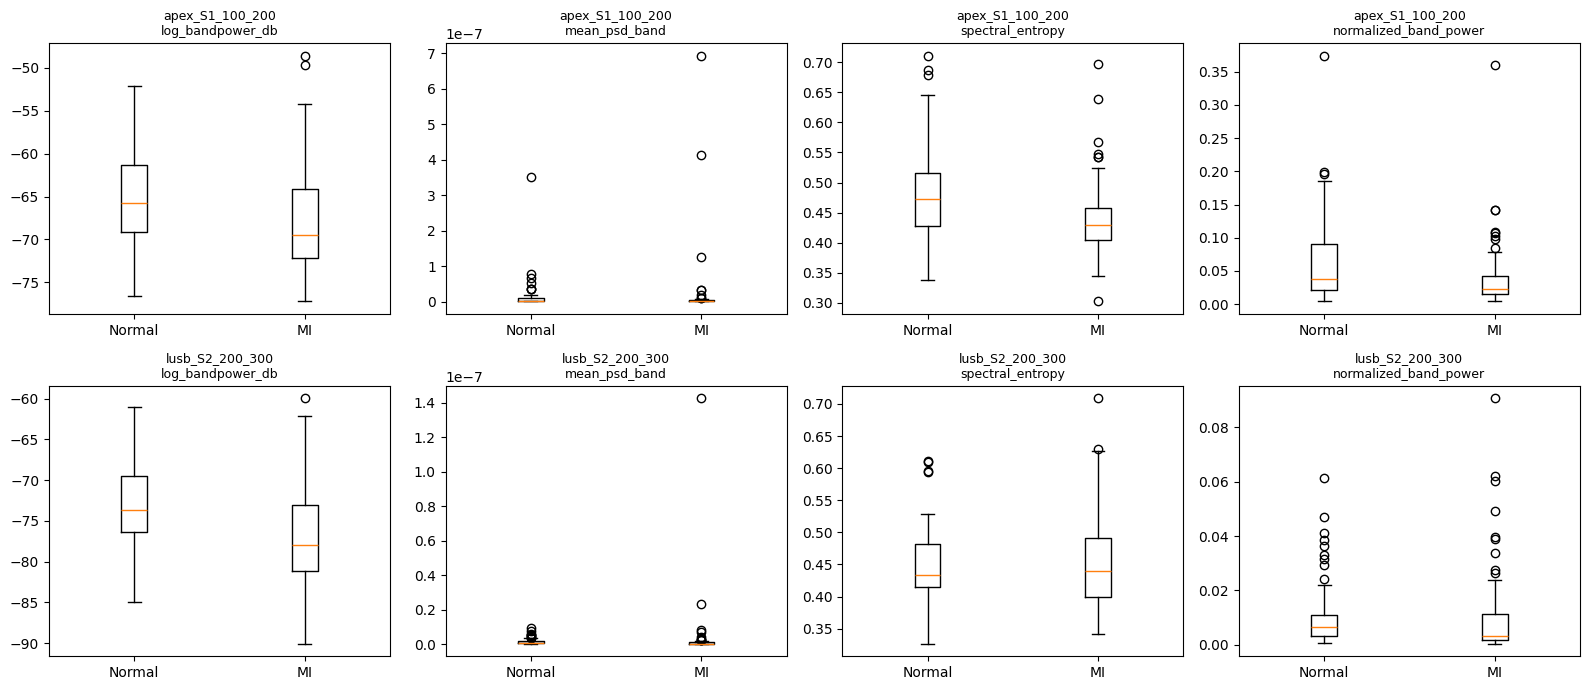

In [9]:
pooled = patient_descriptors
fig, axes = plt.subplots(len(CANDIDATES), len(DESCRIPTOR_COLUMNS),
                         figsize=(4 * len(DESCRIPTOR_COLUMNS), 3.5 * len(CANDIDATES)))
if len(CANDIDATES) == 1:
    axes = axes[None, :]

for i, cand in enumerate(CANDIDATES):
    cand_df = pooled[pooled["candidate"] == cand["name"]]
    for j, col in enumerate(DESCRIPTOR_COLUMNS):
        ax = axes[i, j]
        mi_vals = cand_df.loc[cand_df["class_name"] == config.CLASSES[1], col].dropna()
        normal_vals = cand_df.loc[cand_df["class_name"] == config.CLASSES[0], col].dropna()
        ax.boxplot([normal_vals, mi_vals], tick_labels=["Normal", "MI"])
        ax.set_title(f"{cand['name']}\n{col}", fontsize=9)

plt.tight_layout()
plt.savefig(STAGE_DIR / "signal_domain_boxplots.png", dpi=150)
plt.show()

## 8. Save config + short summary

In [10]:
config_used = {
    "stage": "06_signal_domain_verification",
    "generated": datetime.datetime.now().isoformat(),
    "candidates": CANDIDATES,
    "descriptor_columns": DESCRIPTOR_COLUMNS,
    "filter_order": FILTER_ORDER,
    "sample_rate": config.SAMPLE_RATE,
    "clip_seconds": config.CLIP_SECONDS,
    "frequency_high_total": config.FREQUENCY_HIGH,
    "min_patients_per_group": config.MIN_PATIENTS_PER_GROUP_FOR_TEST,
    "fdr_alpha": config.FDR_ALPHA,
    "bootstrap_n": 2000,
    "bootstrap_ci": 0.95,
    "seed": config.SEED,
    "extended_confirmation_target_per_class": EXTENDED_CONFIRMATION_TARGET_PER_CLASS,
    "extended_confirmation_seed": EXTENDED_CONFIRMATION_SEED,
    "extended_confirmation_composition": extension_log,
}
with open(STAGE_DIR / "config_used.json", "w") as f:
    json.dump(config_used, f, indent=2)

lines = ["# Stage 6 -- Signal-Domain Verification (no Grad-CAM)\n",
        f"Generated: {config_used['generated']}\n\n",
        "Independent, model-free re-test of Stage 4/5's two candidates: band-pass filter "
        "the raw waveform to the candidate band, restrict to the candidate's phase, and "
        "compare MI vs. Normal at the patient level using physical acoustic descriptors.\n\n",
        "`confirmation` (n=14/14) is the only genuine untouched hold-out grouping below; "
        "`confirmation_extended` borrows development patients to check statistical power and "
        "should not be read as independent replication -- see Section 5.\n\n"]

for cohort_label in ["development", "confirmation", "confirmation_extended", "pooled"]:
    lines.append(f"## {cohort_label.replace('_', ' ').capitalize()} cohort\n\n")
    cohort_res = signal_domain_results[signal_domain_results["analysis_cohort"] == cohort_label]
    for cand in CANDIDATES:
        lines.append(f"### {cand['name']}\n\n")
        cand_res = cohort_res[cohort_res["candidate"] == cand["name"]]
        for _, r in cand_res.iterrows():
            flag = "SIGNIFICANT" if r["significant"] else "not significant"
            direction = ""
            if pd.notna(r["matches_gradcam_direction"]):
                direction = " (direction matches Grad-CAM finding)" if r["matches_gradcam_direction"] \
                            else " (direction DOES NOT match Grad-CAM finding)"
            lines.append(
                f"- **{r['descriptor']}**: delta={r['cliffs_delta']:.3f} "
                f"(95% CI [{r['ci_low']:.3f}, {r['ci_high']:.3f}]), "
                f"p={r['p_value']:.4g}, q={r['fdr_q_value']:.4g} -- {flag}{direction}\n"
            )
        lines.append("\n")

with open(STAGE_DIR / "final_report_stage6.md", "w") as f:
    f.writelines(lines)

print("".join(lines))

# Stage 6 -- Signal-Domain Verification (no Grad-CAM)
Generated: 2026-09-16T05:46:23.768852

Independent, model-free re-test of Stage 4/5's two candidates: band-pass filter the raw waveform to the candidate band, restrict to the candidate's phase, and compare MI vs. Normal at the patient level using physical acoustic descriptors.

`confirmation` (n=14/14) is the only genuine untouched hold-out grouping below; `confirmation_extended` borrows development patients to check statistical power and should not be read as independent replication -- see Section 5.

## Development cohort

### apex_S1_100_200

- **log_bandpower_db**: delta=-0.398 (95% CI [-0.583, -0.188]), p=0.0003032, q=0.0005312 -- SIGNIFICANT (direction matches Grad-CAM finding)
- **mean_psd_band**: delta=-0.395 (95% CI [-0.578, -0.190]), p=0.000332, q=0.0005312 -- SIGNIFICANT (direction matches Grad-CAM finding)
- **spectral_entropy**: delta=-0.416 (95% CI [-0.608, -0.212]), p=0.0001621, q=0.0004322 -- SIGNIFICANT
- **normaliz